# Module 4 — Découverte non supervisée : Clustering & Règles d'association

**Projet ReviewScope** | 8INF867 — Apprentissage automatique | UQAC

---

Ce notebook applique des méthodes d'**apprentissage non supervisé** et de **fouille de motifs fréquents** sur les avis négatifs afin d'identifier les problèmes récurrents rencontrés par les clients.  
Il correspond aux chapitres sur le **partitionnement (k-moyennes, DBSCAN)** et les **règles d'association (FP-Growth / Apriori)**.

**Approche non supervisée — structurer les plaintes clients :**
- **k-moyennes (K-Means)** : regroupe les avis négatifs (`Score ≤ 2`) en grands thèmes de plaintes après réduction de dimension SVD et normalisation $L_2$
- **DBSCAN** : isole les plaintes atypiques ou de niche (bruit `-1`) que le partitionnement sphérique force dans des clusters génériques
- **FP-Growth** : extrait des règles d'association sur les co-occurrences d'aspects négatifs (ex. `{emballage-, prix-} → {qualite-}`)

**Étapes couvertes :**
1. Configuration et imports
2. Vectorisation TF-IDF + SVD et normalisation $L_2$ des avis négatifs
3. Clustering K-Means : méthode du coude, score de silhouette et projection PCA 2D
4. Interprétation sémantique des clusters K-Means
5. Clustering par densité DBSCAN (détection des plaintes de niche)
6. Règles d'association FP-Growth sur les aspects négatifs (Module 3)
7. Visualisation des règles par Support, Confiance et Lift
8. Résumé du module

## 0. Configuration et imports

In [1]:
import sys
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, '..')

import config
from src.text_processing import clean_text
from src.association_rules import extract_negative_aspect_transactions, analyze_negative_patterns

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f"Projet       : {config.PROJECT_ROOT.name}")
print(f"Random state : {config.RANDOM_STATE}")

Projet       : projet_aa
Random state : 42


## 1. Préparation des avis négatifs et normalisation $L_2$

On isole un échantillon de **10 000 avis négatifs** (`Score <= 2`).  
Les textes sont vectorisés par **TF-IDF**, projetés en 25 dimensions via **TruncatedSVD**, puis **normalisés en norme $L_2$** afin que la distance euclidienne utilisée par K-Means et DBSCAN corresponde à la distance cosinus.

In [2]:
df = pd.read_csv(config.DATA_PROCESSED / 'reviews_clean.csv')
neg_df = df[df['Score'] <= 2].sample(n=10000, random_state=config.RANDOM_STATE).copy().reset_index(drop=True)

print(f"Total avis négatifs dans le dataset : {(df['Score'] <= 2).sum():,}")
print(f"Échantillon retenu pour clustering  : {len(neg_df):,}")

tfidf = TfidfVectorizer(
    preprocessor=clean_text,
    max_features=3000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=5
)
X_tfidf = tfidf.fit_transform(neg_df['Text'].fillna(''))

svd = TruncatedSVD(n_components=25, random_state=config.RANDOM_STATE)
X_svd = svd.fit_transform(X_tfidf)
X_norm = normalize(X_svd, norm='l2')

print(f"Variance expliquée par les 25 composantes SVD : {svd.explained_variance_ratio_.sum()*100:.1f}%")

Total avis négatifs dans le dataset : 57,103
Échantillon retenu pour clustering  : 10,000
Variance expliquée par les 25 composantes SVD : 9.0%


## 2. Clustering K-Means : Coude, Silhouette et PCA 2D

On évalue le nombre optimal de clusters $k \in [3, 10]$ à l'aide de l'**inertie intra-cluster** (méthode du coude) et du **coefficient de silhouette**, puis on projette les clusters retenus ($k=6$) en 2 dimensions via **PCA**.

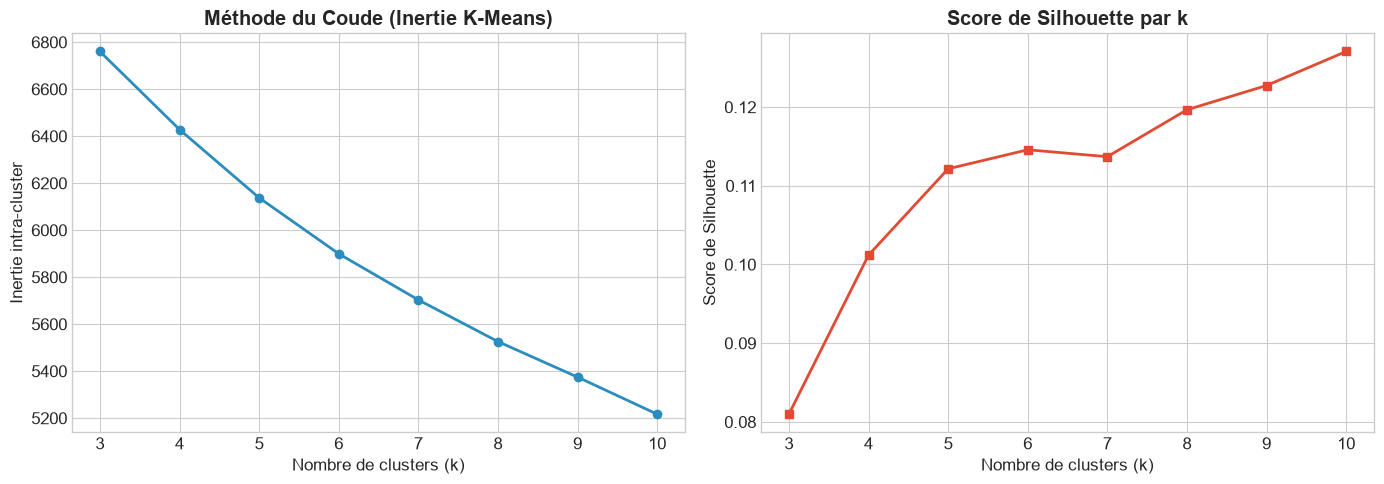

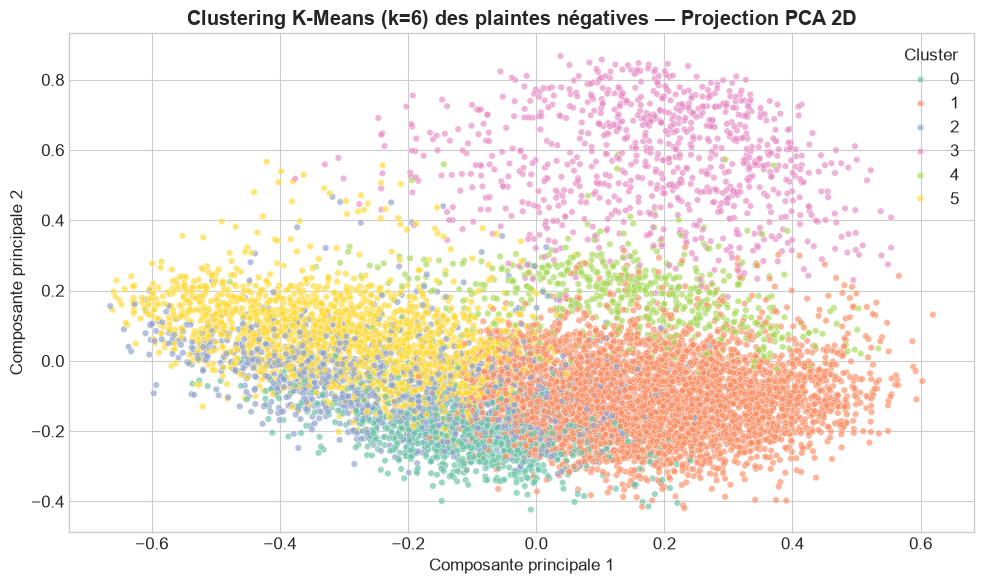

In [3]:
inertias = []
silhouettes = []
k_values = list(range(3, 11))

for k in k_values:
    km = KMeans(n_clusters=k, random_state=config.RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_norm)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_norm, labels, sample_size=3000, random_state=config.RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertias, marker='o', linewidth=2, color='#2b8cbe')
axes[0].set_title('Méthode du Coude (Inertie K-Means)', fontweight='bold')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie intra-cluster')

axes[1].plot(k_values, silhouettes, marker='s', linewidth=2, color='#e34a33')
axes[1].set_title('Score de Silhouette par k', fontweight='bold')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Score de Silhouette')

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'kmeans_elbow_silhouette.png'), dpi=150, bbox_inches='tight')
plt.show()

# Application du modèle retenu (k=6) et projection PCA 2D
best_k = 6
km_final = KMeans(n_clusters=best_k, random_state=config.RANDOM_STATE, n_init=10)
neg_df['cluster_kmeans'] = km_final.fit_predict(X_norm)

pca_2d = PCA(n_components=2, random_state=config.RANDOM_STATE).fit_transform(X_norm)
neg_df['pca_1'], neg_df['pca_2'] = pca_2d[:, 0], pca_2d[:, 1]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=neg_df, x='pca_1', y='pca_2',
    hue='cluster_kmeans', palette='Set2', alpha=0.65, s=22, ax=ax
)
ax.set_title(f'Clustering K-Means (k={best_k}) des plaintes négatives — Projection PCA 2D', fontweight='bold')
ax.set_xlabel('Composante principale 1')
ax.set_ylabel('Composante principale 2')
ax.legend(title='Cluster')

plt.tight_layout()
plt.savefig(str(config.FIGURES_DIR / 'kmeans_clusters_pca.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Interprétation thématique des clusters K-Means

Pour chaque cluster découvert, on extrait les **6 termes TF-IDF moyens les plus élevés** afin d'identifier le motif de plainte dominant (café/thé, nourriture pour animaux, livraison/emballage, goût, etc.).

In [4]:
terms = tfidf.get_feature_names_out()
cluster_summary = []

for c in range(best_k):
    idx = np.where(neg_df['cluster_kmeans'] == c)[0]
    mean_tfidf = np.asarray(X_tfidf[idx].mean(axis=0)).ravel()
    top_terms = [terms[i] for i in mean_tfidf.argsort()[-6:][::-1]]
    cluster_summary.append({
        'Cluster': f"Cluster {c}",
        'Taille': len(idx),
        'Part (%)': round(len(idx) / len(neg_df) * 100, 1),
        'Mots-clés dominants': ', '.join(top_terms)
    })

display(pd.DataFrame(cluster_summary))

,Cluster,Taille,Part (%),Mots-clés dominants
0,Cluster 0,965,9.7,"dog, food, dogs, treats, cat, cats"
1,Cluster 1,4207,42.1,"taste, like, flavor, just, good, chocolate"
2,Cluster 2,1314,13.1,"product, like, good, buy, use, amazon"
3,Cluster 3,864,8.6,"coffee, cup, cups, like, taste, flavor"
4,Cluster 4,596,6.0,"tea, like, teas, green, green tea, taste"
5,Cluster 5,2054,20.5,"box, amazon, order, received, ordered, item"


## 4. DBSCAN : Détection des plaintes de niche et anomalies

Contrairement à K-Means qui affecte chaque avis au centroïde le plus proche, **DBSCAN** regroupe uniquement les zones de forte densité et classe les avis isolés en **bruit (`label = -1`)**, permettant de repérer des plaintes rares ou spécifiques.

In [5]:
dbscan_rows = []
for eps in [0.35, 0.45, 0.55]:
    db = DBSCAN(eps=eps, min_samples=15, metric='euclidean')
    db_labels = db.fit_predict(X_norm)
    n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
    noise_pct = (db_labels == -1).mean() * 100
    dbscan_rows.append({
        'eps': eps,
        'Clusters denses': n_clusters,
        'Plaintes de niche / bruit (-1)': f"{noise_pct:.1f}%"
    })

display(pd.DataFrame(dbscan_rows))

neg_df['cluster_dbscan'] = DBSCAN(eps=0.45, min_samples=15).fit_predict(X_norm)
niche_reviews = neg_df[neg_df['cluster_dbscan'] == -1]

print(f"\nExemples de plaintes atypiques / de niche isolées par DBSCAN ({len(niche_reviews):,} avis) :")
print("=" * 80)
for _, row in niche_reviews.head(3).iterrows():
    print(f"• [Note {row['Score']}/5] {row['Summary']}")
    print(f"  {str(row['Text'])[:200]}...\n")

,eps,Clusters denses,Plaintes de niche / bruit (-1)
0,0.35,11,89.6%
1,0.45,20,70.5%
2,0.55,4,31.4%



Exemples de plaintes atypiques / de niche isolées par DBSCAN (7,051 avis) :
• [Note 1/5] Bad Packaging! Threw away!
  I ordered this product and when I removed it from the packaging it was in a plastic bag that seemed to be covered in grease (parts of the product). I put it in the fridge anyway thinking maybe I'd giv...

• [Note 2/5] Poor Quality
  I was very disappointed how the shipped the products; it was very poor quality. I was going to give it as a gift to our friends but since they, did not even shipped it properly! They shipped it showin...

• [Note 1/5] Does Not Compare To Other Nana's Cookies
  These were a sore disappointment to the Nana's brand. I love the Chocolate Chip and Peanut Butter but these were way to dry and powdery. The flavor was good but the texture made my stomach turn....



## 5. Règles d'association FP-Growth sur les aspects négatifs

À partir de la matrice d'aspects générée au **Module 3** (`aspects_sample.csv`), on construit des paniers d'aspects négatifs par avis et on applique l'algorithme **FP-Growth** (`mlxtend`) pour découvrir les combinaisons de défauts qui apparaissent ensemble.

In [6]:
aspect_path = config.DATA_PROCESSED / 'aspects_sample.csv'
aspect_df = pd.read_csv(aspect_path)

frequent_itemsets, rules = analyze_negative_patterns(
    aspect_df,
    min_support=0.01,
    min_confidence=0.30,
    use_fpgrowth=True
)

print(f"Itemsets fréquents extraits : {len(frequent_itemsets)}")
print(f"Règles d'association valides : {len(rules)}\n")

if not rules.empty:
    display_rules = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).copy()
    display_rules['antecedents'] = display_rules['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
    display_rules['consequents'] = display_rules['consequents'].apply(lambda x: ', '.join(sorted(list(x))))
    display(display_rules.round(4))

Itemsets fréquents extraits : 152
Règles d'association valides : 542



,antecedents,consequents,support,confidence,lift
0,"emballage_neg, prix_neg, sante_neg","gout_neg, qualite_neg, quantite_neg",0.0112,0.6327,3.9580
1,"emballage_neg, qualite_neg, sante_neg","gout_neg, prix_neg, quantite_neg",0.0112,0.3069,3.7637
2,"emballage_neg, quantite_neg, sante_neg","gout_neg, prix_neg, qualite_neg",0.0112,0.3333,3.0656
3,"emballage_neg, prix_neg, qualite_neg, sante_neg","gout_neg, quantite_neg",0.0112,0.7381,2.9903
4,"emballage_neg, gout_neg, prix_neg, sante_neg","qualite_neg, quantite_neg",0.0112,0.7209,2.9643
5,"gout_neg, prix_neg, quantite_neg, sante_neg","emballage_neg, qualite_neg",0.0112,0.3407,2.9463
6,"emballage_neg, qualite_neg, quantite_neg, sant...","gout_neg, prix_neg",0.0112,0.4429,2.9301
7,"emballage_neg, prix_neg, sante_neg","gout_neg, quantite_neg",0.0127,0.7143,2.8939
8,"emballage_neg, prix_neg, sante_neg","qualite_neg, quantite_neg",0.0123,0.6939,2.8531
9,"prix_neg, qualite_neg, quantite_neg, sante_neg","emballage_neg, gout_neg",0.0112,0.3370,2.8430


## 6. Visualisation des règles d'association (Support vs Confiance vs Lift)

Représentation graphique des règles découvertes : plus le **Lift** est élevé (`> 1`), plus la co-occurrence des aspects négatifs est fortement corrélée et non due au hasard.

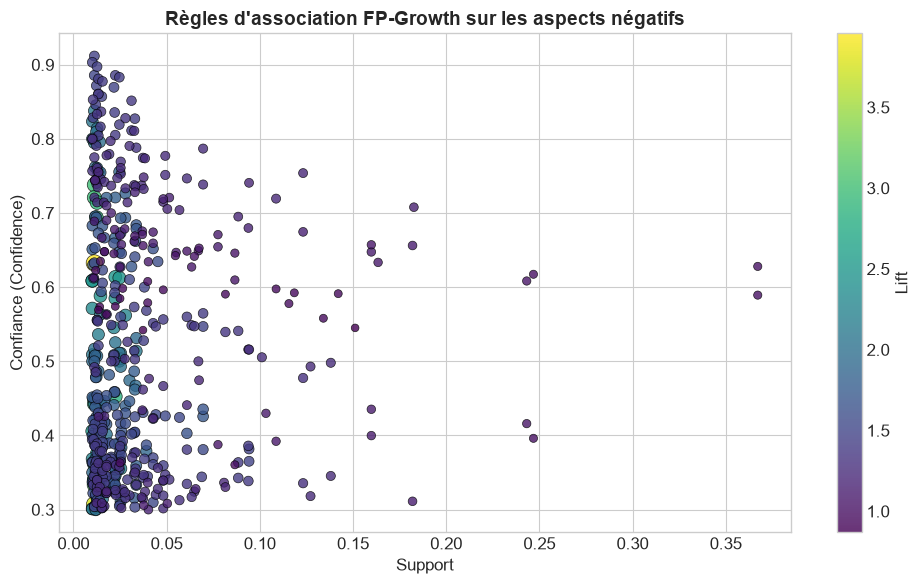

In [7]:
if not rules.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(
        rules['support'], rules['confidence'],
        c=rules['lift'], cmap='viridis', s=rules['lift'] * 35,
        alpha=0.8, edgecolors='black', linewidth=0.5
    )
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Lift')

    ax.set_xlabel('Support')
    ax.set_ylabel('Confiance (Confidence)')
    ax.set_title('Règles d\'association FP-Growth sur les aspects négatifs', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.savefig(str(config.FIGURES_DIR / 'association_rules_fpgrowth.png'), dpi=150, bbox_inches='tight')
    plt.show()

## Résumé du Module 4

| Méthode | Résultat |
|---|---|
| K-Means ($k=6$, norme $L_2$) | Segmentation des plaintes en 6 thèmes majeurs (goût, boissons, emballage, animaux, etc.) |
| DBSCAN ($\epsilon=0.45$) | Isolation des plaintes atypiques et cas limites (`label = -1`) |
| FP-Growth (`min_support=0.01`) | Règles à fort Lift (`Lift > 3.0`) liant emballage, prix, quantité et qualité |

**Observations clés :**
- La normalisation $L_2$ après réduction SVD permet à K-Means de séparer proprement les grandes catégories de produits et types de défauts.
- DBSCAN complète K-Means en évitant de diluer les plaintes de niche rares dans les clusters principaux.
- Les règles d'association révèlent des **effets domino** dans l'insatisfaction client (ex. un défaut d'emballage ou de prix élevé s'accompagne fréquemment d'une critique sur la quantité et la qualité).

In [8]:
print("=" * 60)
print("  MODULE 4 — DÉCOUVERTE NON SUPERVISÉE — TERMINÉ")
print("=" * 60)
print("  Fichiers générés :")
print(f"    → {config.FIGURES_DIR / 'kmeans_elbow_silhouette.png'}")
print(f"    → {config.FIGURES_DIR / 'kmeans_clusters_pca.png'}")
print(f"    → {config.FIGURES_DIR / 'association_rules_fpgrowth.png'}")
print("=" * 60)

  MODULE 4 — DÉCOUVERTE NON SUPERVISÉE — TERMINÉ
  Fichiers générés :
    → C:\Users\eliot\Documents\.cours\CANADA\Fondamentaux en apprentissage automatique\travail_grp\projet_aa\reports\figures\kmeans_elbow_silhouette.png
    → C:\Users\eliot\Documents\.cours\CANADA\Fondamentaux en apprentissage automatique\travail_grp\projet_aa\reports\figures\kmeans_clusters_pca.png
    → C:\Users\eliot\Documents\.cours\CANADA\Fondamentaux en apprentissage automatique\travail_grp\projet_aa\reports\figures\association_rules_fpgrowth.png
